# 03 · Point patterns: Ripley's L, nearest-neighbour index, kernel density

**Question.** Are geocoded bulletins clustered relative to complete spatial randomness (CSR) inside the municipality, at which distances, and does the answer survive removing stacked geocodes? Where is the intensity highest?

**Methods and libraries.**
- **Ripley's K as Besag's L** (Ripley 1976, *J. Applied Probability* 13(2); Besag 1977, discussion, *JRSS B* 39(2)) with Monte Carlo CSR envelopes (Besag & Diggle 1977, *Applied Statistics* 26(3)): `pointpats.distance_statistics.l_test(..., linearized=True)` (pointpats, PySAL; Rey & Anselin 2007), which returns L(d) − d, simulates CSR patterns of the same size inside the `hull` passed and keeps the simulated curves.
- **Average nearest neighbour / Clark–Evans R** (Clark & Evans 1954, *Ecology* 35(4)). pointpats 2.6 has no Clark–Evans function, so nearest-neighbour distances come from `scipy.spatial.cKDTree` and the R, z, p formula is written out in a cell below.
- **Kernel density**: `scipy.stats.gaussian_kde` (Gaussian kernel, Scott's rule bandwidth; Scott 1992, *Multivariate Density Estimation*; Silverman 1986). Display only, no inference.

**Support / window.** The study window W is the **Campinas municipality = union of the 2,592 IBGE 2022 tract polygons** (`load_units("tract").union_all()`), area 794.8 km², EPSG:31983. It includes sparsely settled rural land, so departure from CSR is expected almost by construction (docs/METHODS.md, known limitations).

**Points.** `crime.data.load_points(group)` for the six groups, on (a) **all points** and (b) **distinct locations** (one point per coordinate after rounding the projected coordinates to 1 mm), because ~63 % of bulletins share a published coordinate with another (notebook `01_data_overview`).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pointpats
import shapely
from matplotlib.colors import LogNorm
from pointpats.distance_statistics import l_test
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde, norm

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import GROUPS, load_points, load_units

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

OUT = NOTEBOOK_OUTPUTS_DIR / "03_point_patterns"
OUT.mkdir(parents=True, exist_ok=True)
ms.setup()

SEED = 20251031
DISTANCES = np.arange(100, 3001, 100)   # metres, d = 100 ... 3000 m
N_SIM = 99                              # CSR simulations -> min/max envelope, pointwise two-sided level 2/(99+1) = 0.02
N_SUB = 3000                            # points per Ripley run (subsample, see below)
N_JOBS = 4                              # joblib workers for the simulations (memory: ~0.2 GB each at N_SUB = 3000)
KDE_CELL = 200                          # KDE raster cell size, metres
print("pointpats", pointpats.__version__)

GROUP_COLORS = {"all": "#2a78d6", "property": "#eb6834", "bodily_harm": "#1baf7a",
                "traffic": "#eda100", "drug": "#e87ba4", "violent": "#008300"}
GROUP_LABEL = {"all": "All groups", "property": "Property", "bodily_harm": "Bodily harm",
               "traffic": "Traffic", "drug": "Drug", "violent": "Violent"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

pointpats 2.6.0


In [2]:
tracts = load_units("tract")
WINDOW = tracts.union_all()
AREA_M2 = WINDOW.area
pts_all = load_points("all")
xy_by_group = {}
for g in GROUPS:
    p = pts_all if g == "all" else pts_all[pts_all["group"] == g]
    xy = np.column_stack([p.geometry.x.to_numpy(), p.geometry.y.to_numpy()])
    xy_distinct = np.unique(np.round(xy, 3), axis=0)
    xy_by_group[g] = {"all points": xy, "distinct locations": xy_distinct}
inventory = pd.DataFrame({g: {k: len(v) for k, v in d.items()} for g, d in xy_by_group.items()}).T
inventory["distinct_%"] = (100 * inventory["distinct locations"] / inventory["all points"]).round(1)
print(f"window: {WINDOW.geom_type}, area {AREA_M2/1e6:.1f} km²")
inventory

window: Polygon, area 794.8 km²


,all points,distinct locations,distinct_%
all,107859,50455,46.8
property,90436,45402,50.2
bodily_harm,6590,4736,71.9
traffic,6302,4024,63.9
drug,4032,1893,46.9
violent,499,458,91.8


## 1. Ripley's L with CSR envelopes

**What pointpats 2.6 does (read from `pointpats/distance_statistics.py`).**
- `k()` computes **all** pairwise distances with `scipy.spatial.distance.pdist` (memory O(n²): 107,859 points would need ~47 GB), counts pairs closer than d and divides by the intensity **n / area(bounding box of the pattern)** — the `hull` argument is used only to *simulate* CSR, not for the intensity. Simulated patterns are scored the same way (their own bounding box), so observed and simulated curves share the estimator; the bounding-box areas are printed below.
- **No edge correction** (`edge_correction` raises `NotImplementedError`). Observed and simulated patterns share the window and the bias (docs/METHODS.md §6a).
- `pvalue` is `(#sim ≥ obs + 1)/(N + 1)` folded as `min(p, 1 − p)`; we read the **min/max envelope** of the 99 simulations instead: L(d) − d above the envelope = clustering at distance d at pointwise level 0.02 (Besag & Diggle 1977). Pointwise envelopes over 30 distances are not a global test (Baddeley, Rubak & Turner 2015, *Spatial Point Patterns*, §10.7).

**Subsample.** Because of the O(n²) memory, each run uses a seeded uniform random subsample of `N_SUB = 3,000` points (all 499 violent points; distinct locations are subsampled the same way). Independent random thinning leaves the K function of a stationary process unchanged (Baddeley, Rubak & Turner 2015, §7.4 / thinning property), so the subsample estimates the same K with more noise; CSR is simulated with the same n, so the test is consistent.

In [3]:
x0, y0, x1, y1 = WINDOW.bounds
print(f"window bbox area {((x1-x0)*(y1-y0))/1e6:.1f} km² vs window area {AREA_M2/1e6:.1f} km²")

rng = np.random.default_rng(SEED)
ripley = {}
rows = []
t0 = time.time()
for g in GROUPS:
    for variant, xy in xy_by_group[g].items():
        n = len(xy)
        sub = xy[rng.choice(n, N_SUB, replace=False)] if n > N_SUB else xy
        np.random.seed(SEED)    # seeds this process only: the joblib workers that run pointpats' CSR simulations keep
                                # their own numpy RNG state, so envelopes differ slightly between runs (observed curves do not)
        res = l_test(sub, support=DISTANCES, hull=WINDOW, n_simulations=N_SIM, keep_simulations=True,
                     linearized=True, n_jobs=N_JOBS)
        lo, hi = res.simulations.min(axis=0), res.simulations.max(axis=0)
        ripley[(g, variant)] = (res, lo, hi)
        bx = np.ptp(sub[:, 0]) * np.ptp(sub[:, 1]) / 1e6
        above = res.statistic > hi
        for d, l, a, b, pv in zip(res.support, res.statistic, lo, hi, res.pvalue):
            rows.append({"group": g, "variant": variant, "n_used": len(sub), "n_total": n,
                         "pattern_bbox_km2": bx, "d_m": d, "L_minus_d_m": l,
                         "envelope_lo_m": a, "envelope_hi_m": b, "pointpats_p": pv,
                         "above_envelope": l > b, "below_envelope": l < a})
        print(f"{g:12s} {variant:19s} n={len(sub):5d}/{n:6d}  bbox {bx:6.1f} km²  "
              f"L-d at 500/1000/3000 m = {res.statistic[4]:.0f}/{res.statistic[9]:.0f}/{res.statistic[-1]:.0f} m  "
              f"above envelope at {above.sum()}/{len(above)} d   [{time.time()-t0:.0f}s]")
ripley_tab = pd.DataFrame(rows)
ripley_tab.to_csv(OUT / "ripley_L.csv", index=False)

window bbox area 1636.0 km² vs window area 794.8 km²


all          all points          n= 3000/107859  bbox  982.3 km²  L-d at 500/1000/3000 m = 1608/2634/4758 m  above envelope at 30/30 d   [29s]


all          distinct locations  n= 3000/ 50455  bbox 1264.7 km²  L-d at 500/1000/3000 m = 1189/2104/4554 m  above envelope at 30/30 d   [59s]


property     all points          n= 3000/ 90436  bbox 1010.7 km²  L-d at 500/1000/3000 m = 1759/2806/5164 m  above envelope at 30/30 d   [88s]


property     distinct locations  n= 3000/ 45402  bbox  962.6 km²  L-d at 500/1000/3000 m = 1111/1913/3902 m  above envelope at 30/30 d   [117s]


bodily_harm  all points          n= 3000/  6590  bbox  956.1 km²  L-d at 500/1000/3000 m = 965/1647/3280 m  above envelope at 30/30 d   [143s]


... (3 outputs left out)

drug         all points          n= 3000/  4032  bbox 1080.4 km²  L-d at 500/1000/3000 m = 2581/3285/3733 m  above envelope at 30/30 d   [264s]


drug         distinct locations  n= 1893/  1893  bbox 1179.9 km²  L-d at 500/1000/3000 m = 1365/2038/3154 m  above envelope at 30/30 d   [281s]


violent      all points          n=  499/   499  bbox  806.9 km²  L-d at 500/1000/3000 m = 836/1170/1736 m  above envelope at 30/30 d   [284s]


violent      distinct locations  n=  458/   458  bbox  806.9 km²  L-d at 500/1000/3000 m = 740/1108/1721 m  above envelope at 30/30 d   [287s]


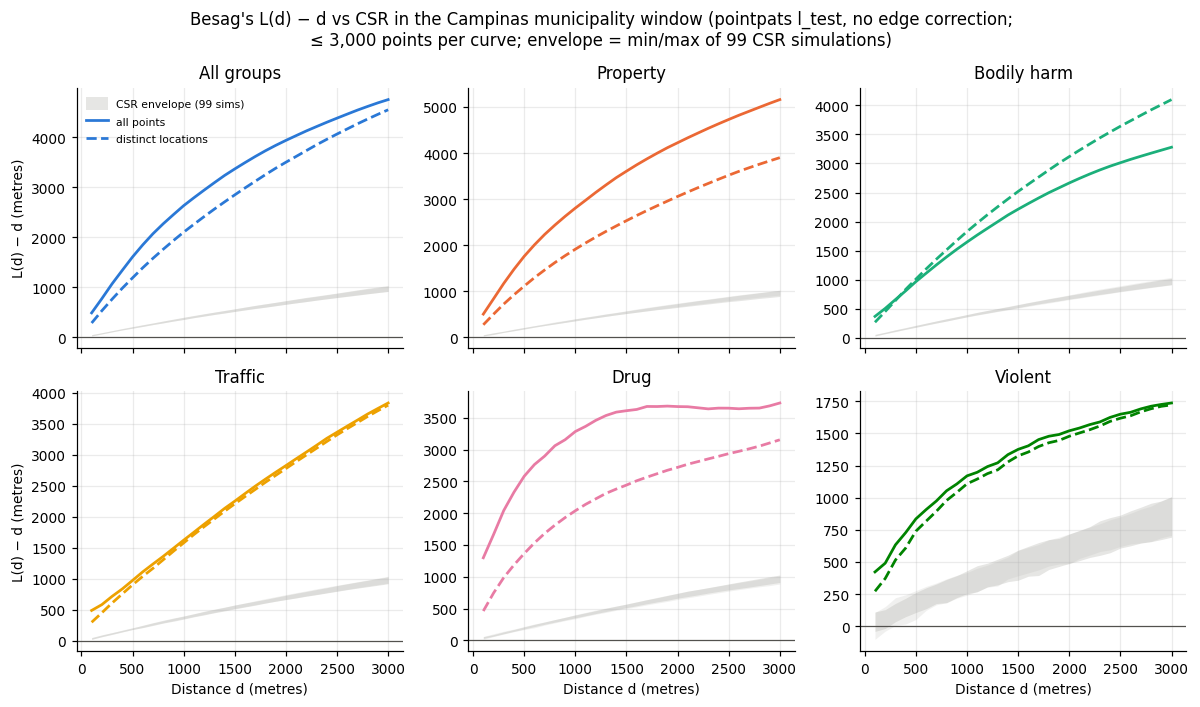

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharex=True)
for ax, g in zip(axes.flat, GROUPS):
    for variant, ls in [("all points", "-"), ("distinct locations", "--")]:
        res, lo, hi = ripley[(g, variant)]
        ax.fill_between(res.support, lo, hi, color="#b8b8b2", alpha=0.35 if ls == "-" else 0.2, lw=0,
                        label=f"CSR envelope ({N_SIM} sims)" if ls == "-" else None)
        ax.plot(res.support, res.statistic, ls, color=GROUP_COLORS[g], lw=1.8, label=variant)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_title(GROUP_LABEL[g])
for ax in axes[:, 0]:
    ax.set_ylabel("L(d) − d (metres)")
for ax in axes[1]:
    ax.set_xlabel("Distance d (metres)")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Besag's L(d) − d vs CSR in the Campinas municipality window (pointpats l_test, no edge correction;\n"
             f"≤ {N_SUB:,} points per curve; envelope = min/max of {N_SIM} CSR simulations)")
fig.tight_layout()
save(fig, "ripley_L_by_group")

In [5]:
summ = (ripley_tab.groupby(["group", "variant"])
        .agg(n_used=("n_used", "first"), n_total=("n_total", "first"),
             d_above_envelope=("above_envelope", "sum"), d_below_envelope=("below_envelope", "sum"),
             L_minus_d_at_500=("L_minus_d_m", lambda s: s.iloc[4]),
             L_minus_d_at_1000=("L_minus_d_m", lambda s: s.iloc[9]),
             L_minus_d_at_3000=("L_minus_d_m", lambda s: s.iloc[-1]),
             max_L_minus_d=("L_minus_d_m", "max"))
        .reindex(GROUPS, level=0))
summ.to_csv(OUT / "ripley_L_summary.csv")
summ.round(0)

n_used  n_total  d_above_envelope  \
group       variant                                                 
all         all points            3000   107859                30   
            distinct locations    3000    50455                30   
property    all points            3000    90436                30   
            distinct locations    3000    45402                30   
bodily_harm all points            3000     6590                30   
            distinct locations    3000     4736                30   
traffic     all points            3000     6302                30   
            distinct locations    3000     4024                30   
drug        all points            3000     4032                30   
            distinct locations    1893     1893                30   
violent     all points             499      499                30   
            distinct locations     458      458                30   

                                d_below_envelope  L_minus_d_at_500  \
group       variant                                                  
all         all points                         0            1608.0   
            distinct locations                 0            1189.0   
property    all points                         0            1759.0   
            distinct locations                 0            1111.0   
bodily_harm all points                         0             965.0   
            distinct locations                 0            1009.0   
traffic     all points                         0             975.0   
            distinct locations                 0             904.0   
drug        all points                         0            2581.0   
            distinct locations                 0            1365.0   
violent     all points                         0             836.0   
            distinct locations                 0             740.0   

                                L_minus_d_at_1000  L_minus_d_at_3000  \
group       variant                                                    
all         all points                     2634.0             4758.0   
            distinct locations             2104.0             4554.0   
property    all points                     2806.0             5164.0   
            distinct locations             1913.0             3902.0   
bodily_harm all points                     1647.0             3280.0   
            distinct locations             1828.0             4100.0   
traffic     all points                     1623.0             3832.0   
            distinct locations             1579.0             3797.0   
drug        all points                     3285.0             3733.0   
            distinct locations             2038.0             3154.0   
violent     all points                     1170.0             1736.0   
            distinct locations             1108.0             1721.0   

                                max_L_minus_d  
group       variant                            
all         all points                 4758.0  
            distinct locations         4554.0  
property    all points                 5164.0  
            distinct locations         3902.0  
bodily_harm all points                 3280.0  
            distinct locations         4100.0  
traffic     all points                 3832.0  
            distinct locations         3797.0  
drug        all points                 3733.0  
            distinct locations         3154.0  
violent     all points                 1736.0  
            distinct locations         1721.0

### Rescaling to the window intensity

The envelopes above are not centred on 0: a CSR pattern filling W has a bounding box of ≈ 1,636 km² against |W| = 794.8 km², so pointpats' intensity n / area(bbox) understates λ and inflates L by $\sqrt{1636/794.8} \approx 1.43$ (L − d ≈ 0.43 d under CSR). The Monte Carlo test is still valid (the same statistic is computed on observed and simulated patterns), but the *values* of L − d are not distances. Since $K = 2\,\#\{\text{pairs} < d\}\,/\,(n\,\lambda)$ with $\lambda = n/\text{area}$, replacing area(bbox) by |W| multiplies K by $|W| / \text{area(bbox)}$, i.e. $L_W(d) = L(d)\sqrt{|W|/\text{area(bbox)}}$ (Ripley 1976 estimator without edge correction, intensity $n/|W|$). The observed curve is rescaled with its own bounding box; the envelope with the window's bounding box, which is approximate (each simulated pattern has its own, slightly smaller, bbox; the gap is largest for the 458–499 violent points). This is an arithmetic correction of the library output, written here because pointpats 2.6 has no window-area option. Under CSR the rescaled envelope sits at ≈ 0 for short distances and drifts below 0 at long ones (≈ −190 m at 3 km): that is the edge effect of the uncorrected estimator, common to observed and simulated curves.

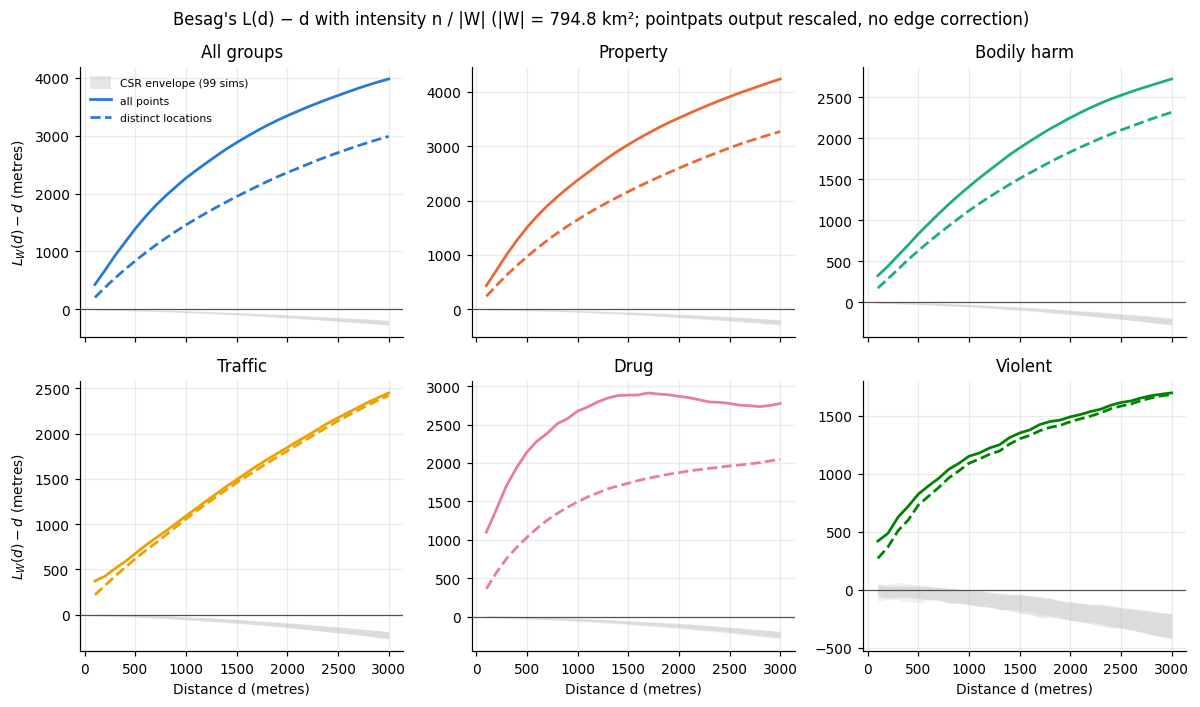

d_m                               500     1000    3000
group       variant                                   
all         all points          1396.0  2269.0  3978.0
            distinct locations   839.0  1460.0  2988.0
property    all points          1503.0  2376.0  4240.0
            distinct locations   964.0  1647.0  3272.0
bodily_harm all points           836.0  1413.0  2725.0
            distinct locations   631.0  1119.0  2321.0
traffic     all points           676.0  1092.0  2449.0
            distinct locations   620.0  1057.0  2421.0
drug        all points          2143.0  2675.0  2775.0
            distinct locations  1031.0  1494.0  2051.0
violent     all points           826.0  1153.0  1700.0
            distinct locations   731.0  1092.0  1685.0

In [6]:
WIN_BBOX_M2 = (x1 - x0) * (y1 - y0)
rt = ripley_tab
rt["L_window_minus_d_m"] = (rt["L_minus_d_m"] + rt["d_m"]) * np.sqrt(AREA_M2 / (rt["pattern_bbox_km2"] * 1e6)) - rt["d_m"]
for c in ["envelope_lo_m", "envelope_hi_m"]:
    rt[c.replace("envelope", "envelope_window")] = (rt[c] + rt["d_m"]) * np.sqrt(AREA_M2 / WIN_BBOX_M2) - rt["d_m"]
rt["above_window_envelope"] = rt["L_window_minus_d_m"] > rt["envelope_window_hi_m"]
rt.to_csv(OUT / "ripley_L.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharex=True)
for ax, g in zip(axes.flat, GROUPS):
    for variant, ls in [("all points", "-"), ("distinct locations", "--")]:
        d = rt[(rt.group == g) & (rt.variant == variant)]
        ax.fill_between(d["d_m"], d["envelope_window_lo_m"], d["envelope_window_hi_m"], color="#b8b8b2",
                        alpha=0.35 if ls == "-" else 0.2, lw=0, label=f"CSR envelope ({N_SIM} sims)" if ls == "-" else None)
        ax.plot(d["d_m"], d["L_window_minus_d_m"], ls, color=GROUP_COLORS[g], lw=1.8, label=variant)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_title(GROUP_LABEL[g])
for ax in axes[:, 0]:
    ax.set_ylabel("$L_W(d) - d$ (metres)")
for ax in axes[1]:
    ax.set_xlabel("Distance d (metres)")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Besag's L(d) − d with intensity n / |W| (|W| = 794.8 km²; pointpats output rescaled, no edge correction)")
fig.tight_layout()
save(fig, "ripley_L_window_intensity")
rt[rt["d_m"].isin([500, 1000, 3000])].pivot_table(index=["group", "variant"], columns="d_m",
    values="L_window_minus_d_m", sort=False).round(0)

## 2. Average nearest neighbour (Clark & Evans 1954)

No pointpats function returns the Clark–Evans index, so the formula is written out. With n points in a window of area A, observed mean nearest-neighbour distance $\bar d_O$ (from `cKDTree.query(k=2)`, the first neighbour being the point itself):

$$\bar d_E = \frac{0.5}{\sqrt{n/A}}, \qquad SE = \frac{0.26136}{\sqrt{n^2/A}}, \qquad R = \frac{\bar d_O}{\bar d_E}, \qquad z = \frac{\bar d_O - \bar d_E}{SE}, \qquad p = 2\,\Phi(-|z|)$$

(Clark & Evans 1954, eqs. for a Poisson process; the same expressions are in Esri, "How Average Nearest Neighbor works"). No edge correction; A = municipality area (794.8 km²). Coincident points (nearest-neighbour distance 0) are counted. All points are used (the k = 1 query is O(n log n)).

In [7]:
rows = []
for g in GROUPS:
    for variant, xy in xy_by_group[g].items():
        n = len(xy)
        d, _ = cKDTree(xy).query(xy, k=2)
        d_obs = d[:, 1].mean()
        d_exp = 0.5 / np.sqrt(n / AREA_M2)
        se = 0.26136 / np.sqrt(n ** 2 / AREA_M2)
        z = (d_obs - d_exp) / se
        rows.append({"group": g, "variant": variant, "n": n, "mean_nn_obs_m": d_obs, "mean_nn_exp_m": d_exp,
                     "R": d_obs / d_exp, "z": z, "p_two_sided": 2 * norm.sf(abs(z)),
                     "median_nn_m": np.median(d[:, 1]), "nn_distance_0_count": int((d[:, 1] == 0).sum()),
                     "nn_distance_0_%": 100 * (d[:, 1] == 0).mean()})
nn = pd.DataFrame(rows)
nn.to_csv(OUT / "clark_evans.csv", index=False)
nn.round(3)

,group,variant,n,mean_nn_obs_m,mean_nn_exp_m,R,z,p_two_sided,median_nn_m,nn_distance_0_count,nn_distance_0_%
0,all,all points,107859,8.788,42.921,0.205,-499.651,0.0,0.000,68037,63.080
1,all,distinct locations,50455,24.080,62.755,0.384,-264.827,0.0,14.380,0,0.000
2,property,all points,90436,10.267,46.874,0.219,-449.299,0.0,0.000,54021,59.734
3,property,distinct locations,45402,25.636,66.155,0.388,-249.670,0.0,15.260,0,0.000
4,bodily_harm,all points,6590,62.972,173.643,0.363,-98.980,0.0,18.573,2643,40.106
5,bodily_harm,distinct locations,4736,102.035,204.830,0.498,-66.071,0.0,73.102,0,0.000
6,traffic,all points,6302,53.193,177.566,0.300,-106.374,0.0,0.000,3054,48.461
7,traffic,distinct locations,4024,103.840,222.213,0.467,-64.646,0.0,65.060,0,0.000
8,drug,all points,4032,54.534,221.993,0.246,-91.635,0.0,0.000,2633,65.303
9,drug,distinct locations,1893,140.474,323.984,0.434,-47.146,0.0,80.439,0,0.000


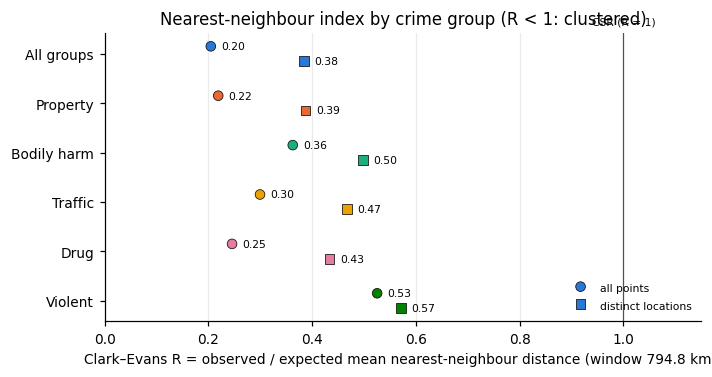

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(GROUPS))[::-1]
for off, variant, mk in [(0.15, "all points", "o"), (-0.15, "distinct locations", "s")]:
    d = nn[nn["variant"] == variant].set_index("group").loc[list(GROUPS)]
    ax.scatter(d["R"], y + off, marker=mk, s=40, c=[GROUP_COLORS[g] for g in GROUPS], edgecolor="#0b0b0b",
               lw=0.5, label=variant, zorder=3)
    for yi, r in zip(y + off, d["R"]):
        ax.text(r + 0.02, yi, f"{r:.2f}", va="center", fontsize=7)
ax.axvline(1, color="#52514e", lw=0.8)
ax.text(1.0, y.max() + 0.6, "CSR (R = 1)", ha="center", fontsize=7)
ax.set_yticks(y, [GROUP_LABEL[g] for g in GROUPS])
ax.set_xlim(0, 1.15)
ax.set_xlabel("Clark–Evans R = observed / expected mean nearest-neighbour distance (window 794.8 km²)")
ax.set_title("Nearest-neighbour index by crime group (R < 1: clustered)")
ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "clark_evans")

## 3. Kernel density surface (all, property)

`scipy.stats.gaussian_kde(xy.T)` with its default **Scott's rule**: the kernel covariance is the sample covariance of the coordinates times $n^{-2/(d+4)} = n^{-1/3}$ (d = 2), i.e. bandwidth factor $n^{-1/6}$ per axis. The density (per m²) × n × 10⁶ gives **bulletins per km²**; evaluated on a 200 m raster clipped to the window. All points are used (stacked points weigh by their multiplicity).

**Not the Esri tool.** Esri "How Kernel Density works" uses the quartic (biweight) kernel and a default search radius from a spatial variant of Silverman's rule, $h = 0.9 \min\!\big(SD, \sqrt{1/\ln 2}\, D_m\big)\, n^{-0.2}$ (SD = standard distance, $D_m$ = median distance to the mean centre). Neither scipy nor scikit-learn offers a quartic kernel (sklearn's nearest is Epanechnikov), so this surface is a Gaussian/Scott KDE; Esri's default radius is printed for comparison only. Note scikit-learn's `bandwidth="scott"/"silverman"` assume standardised data and would give a sub-metre bandwidth on coordinates in metres, which is why scipy is used.

In [9]:
xs = np.arange(x0, x1 + KDE_CELL, KDE_CELL)
ys = np.arange(y0, y1 + KDE_CELL, KDE_CELL)
gx, gy = np.meshgrid(xs + KDE_CELL / 2, ys + KDE_CELL / 2)
inside = shapely.contains_xy(WINDOW, gx.ravel(), gy.ravel())
kde_rows, surfaces = [], {}
for g in ["all", "property"]:
    xy = xy_by_group[g]["all points"]
    n = len(xy)
    t = time.time()
    kde = gaussian_kde(xy.T)                                   # bw_method=None -> Scott's rule
    z = np.full(gx.size, np.nan)
    z[inside] = kde(np.vstack([gx.ravel()[inside], gy.ravel()[inside]])) * n * 1e6
    surfaces[g] = z.reshape(gx.shape)
    sd_axes = np.sqrt(np.diag(kde.covariance))
    mc = xy.mean(axis=0)
    sd_dist = np.sqrt(((xy - mc) ** 2).sum(axis=1).mean())
    dm = np.median(np.sqrt(((xy - mc) ** 2).sum(axis=1)))
    h_esri = 0.9 * min(sd_dist, np.sqrt(1 / np.log(2)) * dm) * n ** -0.2
    kde_rows.append({"group": g, "n": n, "scott_factor": kde.factor, "kernel_sd_x_m": sd_axes[0],
                     "kernel_sd_y_m": sd_axes[1], "esri_default_radius_m_for_reference": h_esri,
                     "max_density_per_km2": np.nanmax(z), "cells": int(inside.sum()), "seconds": time.time() - t})
kde_tab = pd.DataFrame(kde_rows)
kde_tab.to_csv(OUT / "kde_bandwidth.csv", index=False)
kde_tab.round(2)

,group,n,scott_factor,kernel_sd_x_m,kernel_sd_y_m,esri_default_radius_m_for_reference,max_density_per_km2,cells,seconds
0,all,107859,0.14,587.02,712.65,463.28,5616.01,19867,38.94
1,property,90436,0.15,585.53,720.87,448.57,5053.90,19867,31.82


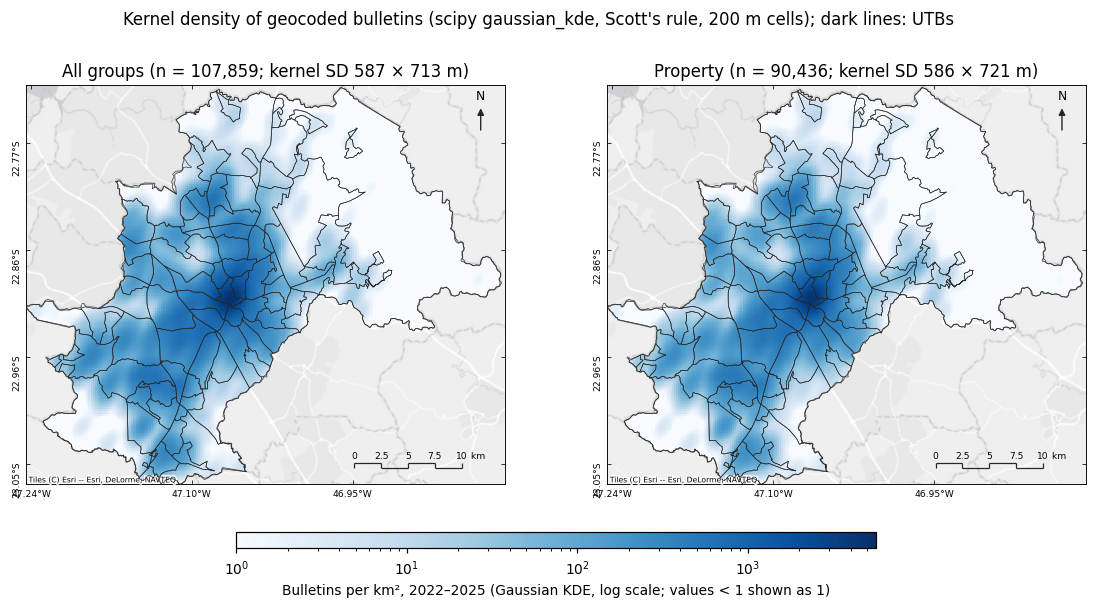

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))
vmax = max(np.nanmax(s) for s in surfaces.values())
for ax, g in zip(axes, ["all", "property"]):
    im = ax.pcolormesh(gx, gy, np.clip(surfaces[g], 1, None), norm=LogNorm(vmin=1, vmax=vmax), cmap="Blues",
                       shading="auto")
    tracts.dissolve().boundary.plot(ax=ax, color="#52514e", lw=0.6)
    ms.decorate(ax, tracts.crs, overlay=load_units("utb"))
    r = kde_tab.set_index("group").loc[g]
    ax.set_title(f"{GROUP_LABEL[g]} (n = {int(r.n):,}; kernel SD {r.kernel_sd_x_m:.0f} × {r.kernel_sd_y_m:.0f} m)")
cb = fig.colorbar(im, ax=axes, orientation="horizontal", shrink=0.6, pad=0.09, aspect=40)
cb.set_label("Bulletins per km², 2022–2025 (Gaussian KDE, log scale; values < 1 shown as 1)")
fig.suptitle(f"Kernel density of geocoded bulletins (scipy gaussian_kde, Scott's rule, {KDE_CELL} m cells); "
             "dark lines: UTBs", y=0.99)
save(fig, "kde_all_property")

## Findings

In [11]:
for (g, v), r in summ.iterrows():
    print(f"{g:12s} {v:19s} L-d @500 {r.L_minus_d_at_500:5.0f} m, @1000 {r.L_minus_d_at_1000:5.0f} m, @3000 {r.L_minus_d_at_3000:5.0f} m; "
          f"above envelope at {r.d_above_envelope}/30 distances")
w = rt.groupby(["group", "variant"], sort=False).agg(
    above=("above_window_envelope", "sum"),
    at500=("L_window_minus_d_m", lambda v: v.iloc[4]), at1000=("L_window_minus_d_m", lambda v: v.iloc[9]),
    at3000=("L_window_minus_d_m", lambda v: v.iloc[-1]), env3000=("envelope_window_hi_m", lambda v: v.iloc[-1]))
print("window-intensity L_W - d:")
print(w.round(0).to_string())
for _, r in nn.iterrows():
    print(f"{r.group:12s} {r.variant:19s} R = {r.R:.3f} (obs {r.mean_nn_obs_m:.0f} m vs exp {r.mean_nn_exp_m:.0f} m), "
          f"z = {r.z:.1f}, NN distance 0: {r['nn_distance_0_%']:.1f}%")

all          all points          L-d @500  1608 m, @1000  2634 m, @3000  4758 m; above envelope at 30.0/30 distances
all          distinct locations  L-d @500  1189 m, @1000  2104 m, @3000  4554 m; above envelope at 30.0/30 distances
property     all points          L-d @500  1759 m, @1000  2806 m, @3000  5164 m; above envelope at 30.0/30 distances
property     distinct locations  L-d @500  1111 m, @1000  1913 m, @3000  3902 m; above envelope at 30.0/30 distances
bodily_harm  all points          L-d @500   965 m, @1000  1647 m, @3000  3280 m; above envelope at 30.0/30 distances
bodily_harm  distinct locations  L-d @500  1009 m, @1000  1828 m, @3000  4100 m; above envelope at 30.0/30 distances
traffic      all points          L-d @500   975 m, @1000  1623 m, @3000  3832 m; above envelope at 30.0/30 distances
traffic      distinct locations  L-d @500   904 m, @1000  1579 m, @3000  3797 m; above envelope at 30.0/30 distances
drug         all points          L-d @500  2581 m, @1000  3285 m

_Written from the numbers printed above (rerun → recheck; the CSR envelopes vary slightly between runs because pointpats' parallel simulations are not seeded)._

- **Distinct locations.** Projected coordinates rounded to 1 mm collapse 107,859 bulletins to 50,455 locations (46.8 %); property 50.2 %, drug 46.9 %, traffic 63.9 %, bodily harm 71.9 %, violent 91.8 %.
- **Ripley's L.** Every group, on all points and on distinct locations, lies above the 99-simulation CSR envelope at all 30 distances from 100 m to 3 km — clustering relative to CSR in the municipality window at every scale tested. With the intensity rescaled to the window area, L_W(d) − d at 1 km is 2,269 m (all points) vs 1,460 m (distinct locations) for all groups, 2,376 vs 1,647 m for property, 2,675 vs 1,494 m for drug, 1,413 vs 1,119 m for bodily harm, 1,092 vs 1,057 m for traffic and 1,153 vs 1,092 m for violent; the CSR envelope is ≈ 0 m there. Removing stacked points lowers the curve most for drug and property (the most stacked groups) but never brings it near the envelope. Drug on all points saturates by ~1.5 km (L_W − d ≈ 2,700–2,900 m from 1.5 to 3 km): its events are concentrated in a few compact areas.
- **Clark–Evans.** R = 0.205 for all points (observed mean nearest-neighbour distance 9 m vs 43 m expected under CSR; z = −500) and 0.384 on distinct locations (24 m vs 63 m). Property 0.219 / 0.388, bodily harm 0.363 / 0.498, traffic 0.300 / 0.467, drug 0.246 / 0.434, violent 0.525 / 0.571; all p ≈ 0. 63.1 % of all points have a nearest neighbour at distance 0 (stacked), which alone pulls R down; distinct locations remove that and R stays well below 1.
- **Caveats.** The window includes rural land, so "clustered vs CSR" is expected by construction; the absolute L values are from an estimator without edge correction; Ripley runs use ≤ 3,000-point random subsamples (pointpats' O(n²) memory). These results say the points are not CSR — they do not locate clusters or separate crime concentration from the concentration of the urban population.
- **KDE.** Scott's rule on all bulletins gives a Gaussian kernel SD of 587 × 713 m (property 586 × 721 m); Esri's default radius rule would give ≈ 463 m (property 449 m) with a quartic kernel. The surface peaks at ≈ 5,600 bulletins per km² (2022–2025) in the central area, with secondary ridges along the south-west and north-west urban axes; property looks the same.